In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors


import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [3]:
from config import *


In [4]:
def get_df(graph_code,pop_size,update,r):
    output_name = f"Moran-N-{pop_size}-geom-{graph_code}-r-{r}-u-{update}"
    with open(f'{results_loc}{output_name}.txt', 'r') as file:
        lines = file.readlines()
    
    test_string = "# index,	stattimes"
    prob_data_lines = []
    time_data_lines = []
    res_time_data_lines = []
    prob = True
    for line in lines:
        if line.strip() and line[0].isdigit():
            if prob:
                prob_data_lines.append(line)
            else:
                time_data_lines.append(line.split(';')[0])
                res_time_data_lines.append(line.split(';')[1])
        if line[:len(test_string)]==test_string:
            prob = False
    prob_data = [line.strip().split(',') for line in prob_data_lines]
    time_data = [line.replace('-','0').strip().split(',') for line in time_data_lines]
    res_time_data = [line.replace('-','0').strip().split(',') for line in res_time_data_lines]
    time_data_cleaned = []
    for value in time_data:
        new_val = []
        for string in value:
            if "±" in string:
                if 'âˆž' in string:
                    mean = 0
                    uncertainty = 0
                else:
                    mean, uncertainty = string.strip().split(" ± ")
                    new_val.append(float(mean.strip()))
                    new_val.append(float(uncertainty.strip()))
            else:
                new_val.append(string.strip())
        time_data_cleaned.append(new_val)
        
    res_time_data_cleaned = []
    for value_ind,value in enumerate(res_time_data):
        new_val = [str(value_ind)]
        for string in value:
            if "±" in string:
                if 'âˆž' in string:
                    mean = 0
                    uncertainty = 0
                else:
                    mean, uncertainty = string.strip().split(" ± ")
                    new_val.append(float(mean.strip()))
                    new_val.append(float(uncertainty.strip()))
            else:
                new_val.append(string.strip())
        res_time_data_cleaned.append(new_val)

    columns = ['node_index','time','time_std','mut_samples']
    time_df = pd.DataFrame(time_data_cleaned,columns = columns)

    columns = ['node_index','res_time','res_time_std','res_samples']
    res_time_df = pd.DataFrame(res_time_data_cleaned,columns = columns)

    columns = ['node_index','fix','no-fix','samples']
    prob_df = pd.DataFrame(prob_data, columns=columns)

    df= pd.merge(time_df,prob_df,how='inner',on="node_index")
    df = pd.merge(df,res_time_df,how='inner',on='node_index')
    for column in df.columns:
        df[column] = pd.to_numeric(df[column])
    return df

def get_prob_mean_and_cis(df):
    df_filtered = df[df['samples']!=0]
    mean = (df_filtered['fix']*df_filtered['samples']/df_filtered['samples'].sum()).sum()
    zalpha = 1.96
    ci = zalpha*np.sqrt(mean*(1-mean)/(df_filtered['samples'].sum()))
    return mean,ci

def get_time_mean_and_cis(df):
    df_filtered = df[df['mut_samples']!=0]
    mean = (df_filtered['time']*df_filtered['mut_samples']/df_filtered['mut_samples'].sum()).sum()
    ci = 0
    return mean,ci

def get_res_time_mean_and_cis(df):
    df_filtered = df[df['res_samples']!=0]
    mean = (df_filtered['res_time']*df_filtered['res_samples']/df_filtered['res_samples'].sum()).sum()
    ci = 0
    return mean,ci
    
def get_Bd_fix_prob(N,r):
    return (1-1/r)/(1-1/r**N)

def get_dB_fix_prob(N):
    r=2
    return (1-1/N)*(1-1/r)/(1-1/r**(N-1))

In [5]:
k_colours = list(mcolors.TABLEAU_COLORS.values())
line_styles = {'Bd':'--', 'dB':':'}

In [ ]:
graph_plots = []
r=2
for graph in graphs: 
    sub_plots = []   
    if graph['code']=='r':
        for update in graph["updates"]:
            graph_plot_means = []
            graph_plot_cis = []
            graph_plot_rs = []
            for k in ks:
                
                try:
                    df = get_df(graph['code']+str(k),graph['pop_size'],update,r)
                except FileNotFoundError as e:
                    print('Missing File',e)
                    continue
                mean,ci = get_prob_mean_and_cis(df)
                graph_plot_rs.append(k)
                graph_plot_means.append(mean)
                graph_plot_cis.append(ci)
            sub_plots.append({
                "means":graph_plot_means,
                "cis":graph_plot_cis,
                "rs":graph_plot_rs,
                "name":f"Regular graph {update}",
                "style":line_styles[update],
                # "colour":k_colours[k],
            })
                
    else:
        for update in graph['updates']:
            graph_plot_means = []
            graph_plot_cis = []
            graph_plot_rs = []
            for r in rs:
                try:
                    df = get_df(graph['code'],graph['pop_size'],update,r)
                except FileNotFoundError as e:
                    print('Missing File',e)
                    continue
                mean,ci = get_prob_mean_and_cis(df)
                graph_plot_rs.append(r)
                graph_plot_means.append(mean)
                graph_plot_cis.append(ci)
            sub_plots.append({
                "means":graph_plot_means,
                "cis":graph_plot_cis,
                "rs":graph_plot_rs,
                "name":f"Regular graph {update}",
                "style":line_styles[update],
                # "colour":k_colours[k],
            })
    graph_plots.append(sub_plots)

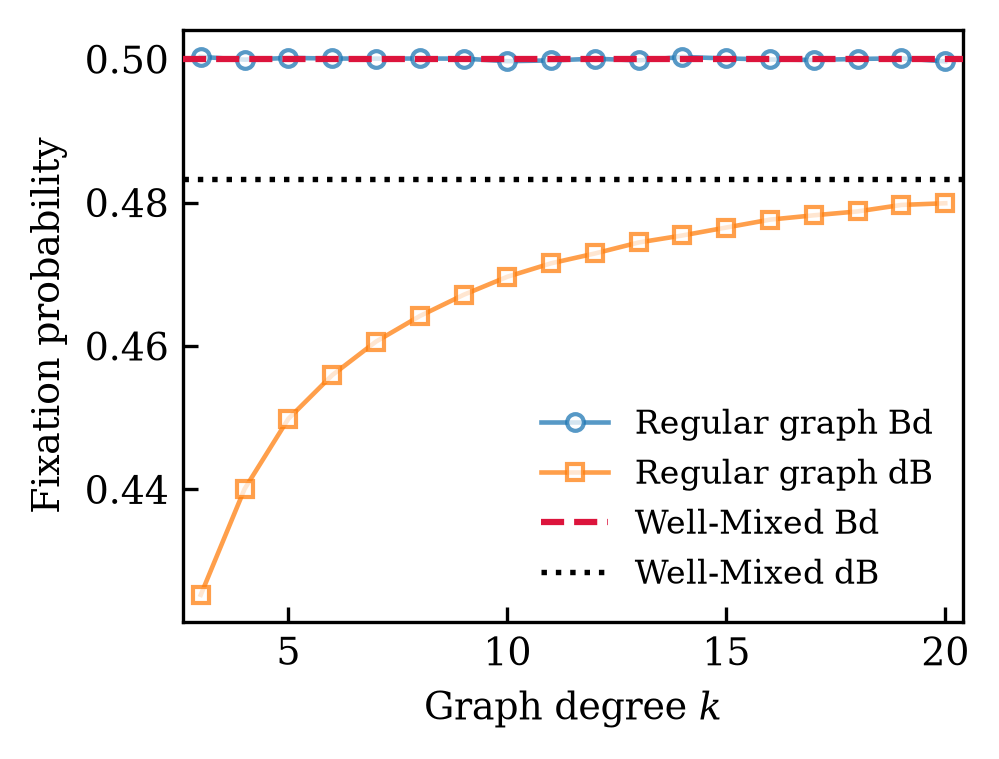

In [ ]:
import itertools

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "dejavuserif",
    "font.size": 9,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": False,
    "ytick.right": False,
    "legend.fontsize": 8,
})

markers = itertools.cycle(["o", "s", "D", "^", "v", "P"])

for idx, sub_plots in enumerate(graph_plots):
    fig, ax = plt.subplots(figsize=(3.4, 2.6), dpi=300)

    for graph_plot in sub_plots:
        ax.plot(
            graph_plot['rs'],
            graph_plot['means'],
            marker=next(markers),
            markersize=4,
            markerfacecolor='white',
            linewidth=1.1,
            zorder=2,
            label=graph_plot['name'],
            alpha=0.75
        )

    N = 30
    Bd_fix_prob = (1 - 1/2) / (1 - 1/2**N)
    dB_fix_prob = (1 - 1/N) * (1 - 1/2) / (1 - 1/2**(N-1))

    ax.axhline(Bd_fix_prob, color='crimson', linestyle='--', linewidth=1.5,
               zorder=3, label=r"Well-Mixed Bd")
    ax.axhline(dB_fix_prob, color='black', linestyle=':', linewidth=1.3,
               zorder=3, label=r"Well-Mixed dB")

    ax.set_xlabel(r"Graph degree $k$")
    ax.set_ylabel(r"Fixation probability")
    ax.set_xlim(2.6, 20.4)

    ax.legend(frameon=False, loc='best')
    fig.tight_layout()

    fig.savefig(f"Moran_fixation_vs_degree_{idx}.pdf", bbox_inches="tight")
